# 08 · Posteriors with MCMC

`lenscape.mcmc` is an affine-invariant ensemble sampler (Goodman & Weare 2010). The log-probability is any
function of the parameter vector, here −χ²/2 of the binary-lens model with flat priors.

> **Runtime.** The chain below (24 walkers × 400 steps) takes a few minutes. Publication-quality posteriors need
> chains of several thousand steps (≳ 50 autocorrelation times); increase `nsteps` accordingly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
from lenscape import mcmc, model

In [2]:
data = lenscape.datasets.kmtnet("KMT-2022-BLG-0114", window=(9600, 9720))
p0 = np.array([9657.785, -0.02614, 34.51, np.log10(1.0033), np.log10(4.36e-3), 4.354, -3.0])
_, best = lenscape.fit_full(data, p0)
data = data.scale_errors(lenscape.error_factors(data, best))
_, best = lenscape.fit_full(data, best)
backend = lenscape.make_backend(config.REFINE_BACKEND)
lp = lambda p: -0.5 * model.chi2(backend, p, data)

In [3]:
nsteps = 400
scale = np.array([0.005, 2e-4, 0.2, 2e-4, 0.01, 0.005, 0.05])        # initial spread of the walkers
run = mcmc.run(lp, best, scale, nwalkers=24, nsteps=nsteps, workers=4, seed=1)
print("acceptance fraction:", run["acc"].mean().round(2))

acceptance fraction: 0.32


In [4]:
chain = run["chain"][:, nsteps // 2:]                                  # discard the first half as burn-in
print("autocorrelation times (steps):", mcmc.autocorr_time(chain).round(0))
names = ["t0", "u0", "tE", "log s", "log q", "alpha", "log rho"]
for name, med, lo, hi in mcmc.summary(chain, names):
    print(f"{name:8s} {med:12.5f}  -{lo:.5f} +{hi:.5f}")

autocorrelation times (steps): [24. 20. 21. 22. 22. 22. 19.]
t0         9657.79522  -0.01901 +0.02153
u0           -0.02650  -0.00150 +0.00085
tE           36.22531  -1.57009 +1.25570
log s         0.00045  -0.00125 +0.00144
log q        -2.42671  -0.03710 +0.05316
alpha         4.22380  -0.09468 +0.09807
log rho      -3.10862  -0.95663 +0.48172


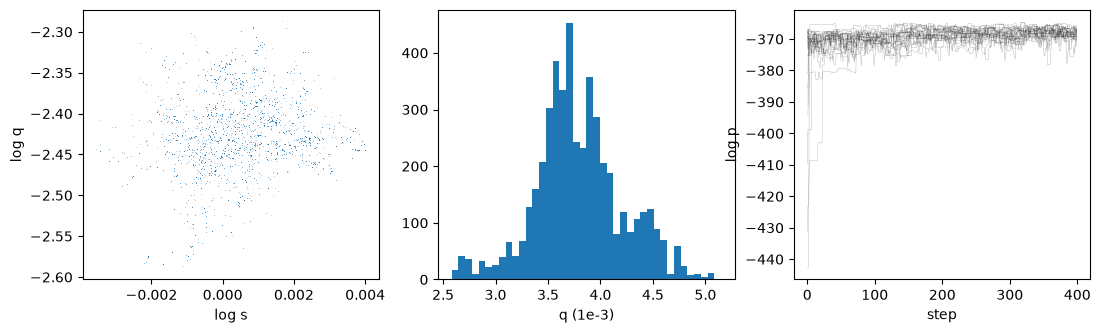

In [5]:
flat = chain.reshape(-1, 7)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(flat[:, 3], flat[:, 4], ",", alpha=0.3); ax[0].set_xlabel("log s"); ax[0].set_ylabel("log q")
ax[1].hist(10 ** flat[:, 4] * 1e3, 40); ax[1].set_xlabel("q (1e-3)")
ax[2].plot(run["lnp"].T, lw=0.3, color="k", alpha=0.3); ax[2].set_xlabel("step"); ax[2].set_ylabel("log p");